# Адаптивное семплирование RAD для PINN

Проверяем, позволяет ли отбор точек по невязке LLE уменьшить число внутренних точек и время расчета при обучении одной PINN на всем интервале [0, 4]. В [эксперименте 5](../05_pinn-single-soliton/single-soliton-pinn.ipynb) равномерная выборка с 32 768 точками и обновлением каждые 100 шагов дала 1,90% максимальной ошибки за 480 000 шагов. Здесь используем новый равномерный контроль на том же GPU и с тем же бюджетом, что у RAD.

## Постановка

- 12 обучений с нуля по 500 000 шагов Adam на RTX 4090. Сравниваем 8 192, 16 384 и 32 768 внутренних точек, два периода обновления (100 и 1 000 шагов) и два способа отбора (равномерный и RAD).
- Во всех запусках одна постановка LLE и тот же начальный гауссов импульс, что в эксперименте 5. Сеть имеет четыре скрытых слоя шириной 64 и четыре пространственные гармоники. Используем seed 42, learning rate 0.001, 256 начальных точек и вес начального условия 10.
- RAD начинает адаптацию на шаге 5 000. При каждом обновлении отбирает N точек с возвращением из 131 072 равномерных кандидатов. Половина вероятности распределена равномерно, вторая половина пропорциональна модулю невязки LLE.

[Конфигурация серии](rad_config.yaml) | [Скрипт запуска](../../scripts/_run_pinn_sweep.py)

In [1]:
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.colors import TwoSlopeNorm

from lle.analysis.fields import relative_l2_error
from lle.runs.runs import get_run
from lle.storage import load_evolution
from lle.workflows.pinn_gaussian.config import PinnGaussianConfig

REFERENCE_RUN_ID = "2026-11-10_07-44-12_914080"
POINT_COUNTS = (32_768, 16_384, 8_192)
PERIODS = (1_000, 100)
SAMPLERS = ("uniform", "rad")

# В каждой строке сначала равномерный запуск, затем RAD.
run_ids = {
    (32_768, 1_000): ("2026-11-21_05-08-31_689988", "2026-11-21_06-27-32_060800"),
    (32_768, 100): ("2026-11-21_07-48-25_600230", "2026-11-21_09-07-53_106062"),
    (16_384, 1_000): ("2026-11-21_10-35-33_367276", "2026-11-21_11-45-48_774026"),
    (16_384, 100): ("2026-11-21_12-56-55_547319", "2026-11-21_14-07-17_731354"),
    (8_192, 1_000): ("2026-11-21_15-25-37_139338", "2026-11-21_16-35-48_370347"),
    (8_192, 100): ("2026-11-21_17-46-40_451027", "2026-11-21_18-57-38_683947"),
}

reference = load_evolution(get_run(REFERENCE_RUN_ID).path)
times = reference.times
fields, errors, elapsed_minutes, paths = {}, {}, {}, {}
common_config = None

for (points, period), ids in run_ids.items():
    for sampler, run_id in zip(SAMPLERS, ids, strict=True):
        key = points, period, sampler
        run = get_run(run_id)
        config = run.load_config(PinnGaussianConfig)
        metadata = run.load_metadata()
        assert metadata["status"] == "complete"
        assert config.training.iterations == 500_000 and config.domain.time_end == 4.0
        assert config.domain.interior_points == points
        assert config.training.resample_every == period
        assert (config.sampling.rad is not None) == (sampler == "rad")
        assert metadata["runtime"]["device_name"] == "NVIDIA GeForce RTX 4090"

        fixed = config.model_dump(exclude={
            "domain": {"interior_points"},
            "training": {"resample_every"},
            "sampling": True,
        })
        if common_config is None:
            common_config = fixed
        assert fixed == common_config

        field = load_evolution(run.path)
        np.testing.assert_array_equal(field.theta, reference.theta)
        np.testing.assert_allclose(field.times, times, rtol=0, atol=1e-10)
        fields[key] = field
        errors[key] = 100 * relative_l2_error(field.values, reference.values)
        start = datetime.fromisoformat(metadata["started_utc"])
        finish = datetime.fromisoformat(metadata["finished_utc"])
        elapsed_minutes[key] = (finish - start).total_seconds() / 60
        paths[key] = run.path

## Точность и время

Эталон SSFM из эксперимента 5 (2026-11-10_07-44-12_914080) рассчитан с шагом 0.0005. Сравниваем комплексные поля на 512 пространственных узлах и 401 сохраненном временном срезе с интервалом 0.01. Для каждого среза считаем относительную L2-ошибку по пространству, затем берем максимум по сохраненным срезам. Критерий из эксперимента 5 выполнен при максимуме до 5%. Время берем из метаданных полного запуска, включая отбор точек и сохранение результатов.

In [2]:
def decimal(value):
    return f"{value:.2f}".replace(".", ",")


rows = [
    "| Точки | Период | Ошибка, равн. | Ошибка, RAD | Мин, равн. | Мин, RAD |",
    "| ---: | ---: | ---: | ---: | ---: | ---: |",
]
for points, period in run_ids:
    uniform = points, period, "uniform"
    rad = points, period, "rad"
    point_label = f"{points:,}".replace(",", " ")
    period_label = f"{period:,}".replace(",", " ")
    rows.append(
        f"| {point_label} | {period_label} | {decimal(errors[uniform].max())}% | "
        f"{decimal(errors[rad].max())}% | {decimal(elapsed_minutes[uniform])} | "
        f"{decimal(elapsed_minutes[rad])} |"
    )
display(Markdown("\n".join(rows)))

| Точки | Период | Ошибка, равн. | Ошибка, RAD | Мин, равн. | Мин, RAD |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 32 768 | 1 000 | 83,77% | 71,02% | 78,97 | 80,86 |
| 32 768 | 100 | 1,95% | 22,07% | 79,42 | 87,63 |
| 16 384 | 1 000 | 83,38% | 71,83% | 70,22 | 71,08 |
| 16 384 | 100 | 72,17% | 2,46% | 70,34 | 78,29 |
| 8 192 | 1 000 | 83,47% | 81,97% | 70,15 | 70,83 |
| 8 192 | 100 | 73,89% | 2,76% | 70,94 | 77,74 |

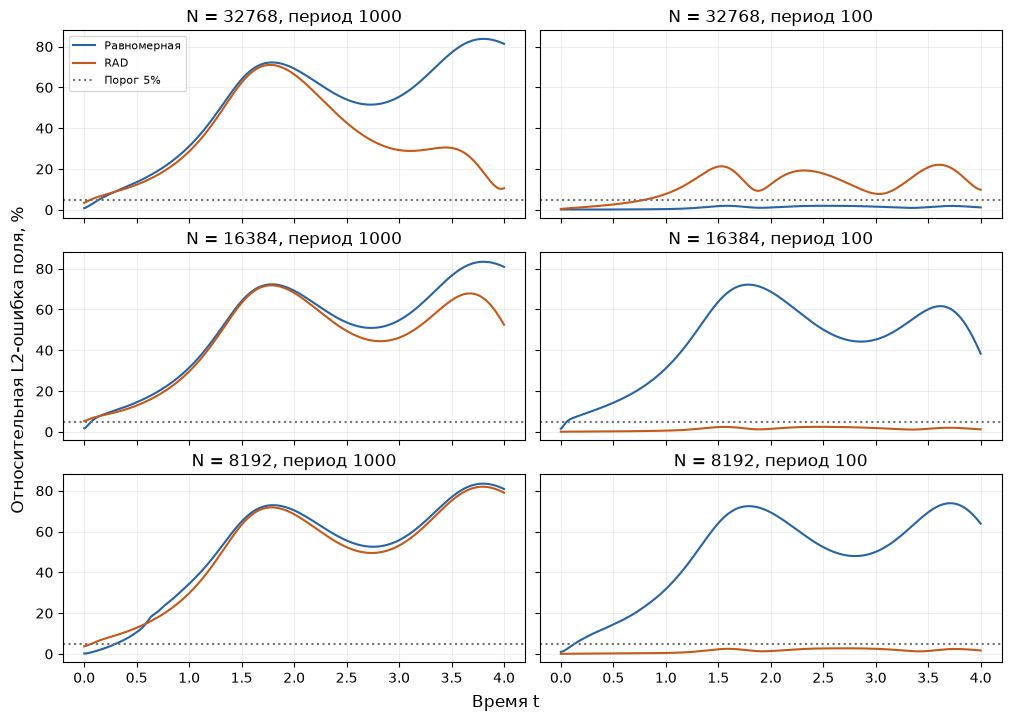

In [3]:
colors = {"uniform": "#2764a5", "rad": "#c75918"}
labels = {"uniform": "Равномерная", "rad": "RAD"}

fig, axes = plt.subplots(3, 2, figsize=(10, 7.1), sharex=True, sharey=True, layout="constrained")
for i, points in enumerate(POINT_COUNTS):
    for j, period in enumerate(PERIODS):
        ax = axes[i, j]
        for sampler in SAMPLERS:
            ax.plot(times, errors[points, period, sampler], label=labels[sampler], color=colors[sampler])
        ax.axhline(5, color="0.45", linestyle=":", label="Порог 5%")
        ax.set_title(f"N = {points}, период {period}")
        ax.grid(alpha=0.2)

axes[0, 0].legend(loc="upper left", fontsize=8)
fig.supxlabel("Время t")
fig.supylabel("Относительная L2-ошибка поля, %")
plt.show()

### Профили интенсивности

Срезы при t = 1.48, 3.50 и 4.00 показывают, что RAD на 8 192 точках воспроизводит форму и высоту пиков примерно так же, как равномерный контроль на 32 768 точках. При том же N = 8 192 у равномерного варианта оба пика при t = 1.48 и 3.50 сильно занижены. Точность фазы учитывается в метрике комплексного поля выше.

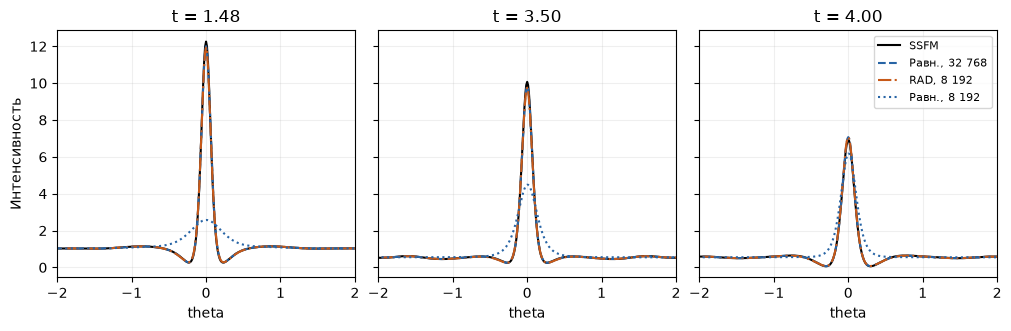

In [4]:
profile_cases = (
    (reference, "SSFM", "black", "-"),
    (fields[32_768, 100, "uniform"], "Равн., 32 768", colors["uniform"], "--"),
    (fields[8_192, 100, "rad"], "RAD, 8 192", colors["rad"], "-."),
    (fields[8_192, 100, "uniform"], "Равн., 8 192", colors["uniform"], ":"),
)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True, layout="constrained")
for ax, time in zip(axes, (1.48, 3.5, 4.0), strict=True):
    frame = np.argmin(np.abs(times - time))
    for field, label, color, style in profile_cases:
        ax.plot(field.theta, field.intensity.values[frame], style, color=color, label=label)
    ax.set(title=f"t = {time:.2f}", xlabel="theta", xlim=(-2, 2))
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Интенсивность")
axes[-1].legend(fontsize=8)
plt.show()

## Динамика потерь

Суммируем две компоненты PDE-loss (для действительной и мнимой частей). Для оценки перелома используем тот же расчет, что в эксперименте 5. Для каждого шага от 15 000 до 490 000 сравниваем медиану за предыдущие 5 000 шагов с большей из медиан в двух следующих окнах по 5 000. Для train и test получаем два отношения и берем меньшее из них. На графиках отмечаем максимум этого показателя, если он не ниже 2.5. Проверочная выборка сохраняется при обновлениях внутри запуска. Ее размер зависит от N, поэтому итоговую точность между запусками сравниваем на общей сетке SSFM. Графики начинаются с шага 5 000, когда включается RAD.

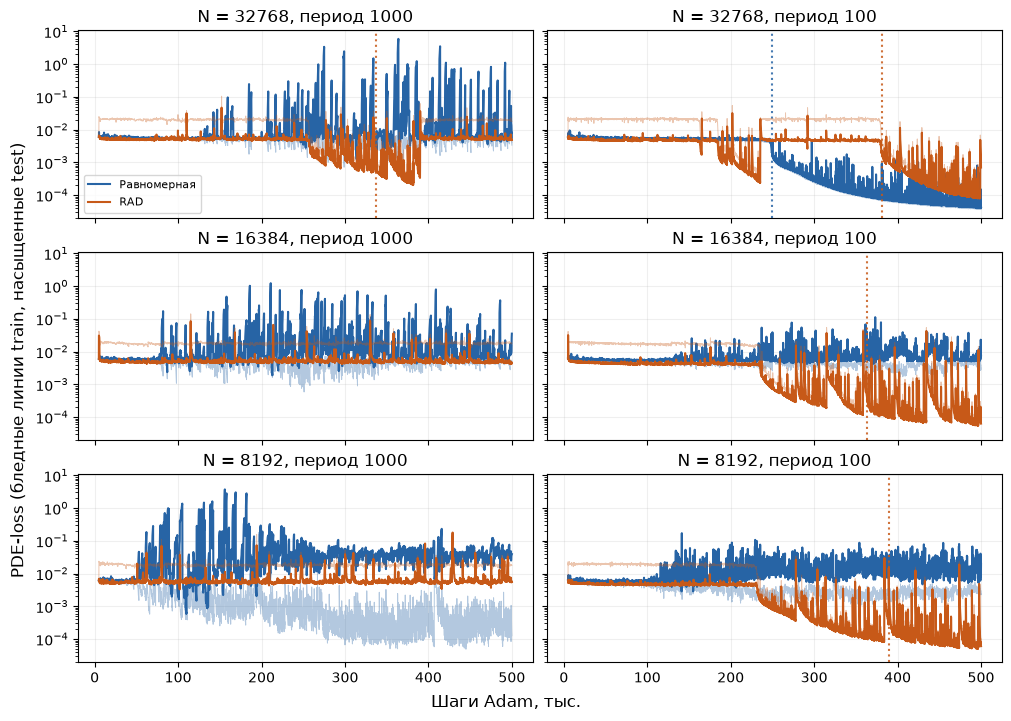

In [5]:
def loss_transition(steps, pde):
    candidates = steps[(steps >= 15_000) & (steps <= steps[-1] - 10_000)]
    best_step, best_ratio = None, 0.0
    for step in candidates:
        a, b, c, d = np.searchsorted(steps, [step - 5_000, step, step + 5_000, step + 10_000])
        before = np.median(pde[a:b], axis=0)
        after = np.maximum(np.median(pde[b:c], axis=0), np.median(pde[c:d], axis=0))
        ratio = (before / after).min()
        if ratio > best_ratio:
            best_step, best_ratio = step, ratio
    return best_step if best_ratio >= 2.5 else None


fig, axes = plt.subplots(3, 2, figsize=(10, 7.1), sharex=True, sharey=True, layout="constrained")
transitions = {}
for i, points in enumerate(POINT_COUNTS):
    for j, period in enumerate(PERIODS):
        ax = axes[i, j]
        for sampler in SAMPLERS:
            key = points, period, sampler
            losses = np.genfromtxt(paths[key] / "losses.csv", delimiter=",", names=True)
            steps = losses["step"].astype(int)
            np.testing.assert_array_equal(steps, np.arange(0, 500_001, 100))
            pde = np.column_stack([
                losses[f"{split}_pde_u"] + losses[f"{split}_pde_v"]
                for split in ("train", "test")
            ])
            assert np.isfinite(pde).all() and (pde > 0).all()
            color = colors[sampler]
            shown = steps >= 5_000
            ax.semilogy(steps[shown] / 1000, pde[shown, 1], color=color, label=labels[sampler])
            ax.semilogy(steps[shown] / 1000, pde[shown, 0], color=color, alpha=0.35, linewidth=0.7)
            step = loss_transition(steps, pde)
            transitions[key] = step
            if step is not None:
                ax.axvline(step / 1000, color=color, linestyle=":", alpha=0.85)
        ax.set_title(f"N = {points}, период {period}")
        ax.grid(alpha=0.2)

axes[0, 0].legend(loc="lower left", fontsize=8)
fig.supxlabel("Шаги Adam, тыс.")
fig.supylabel("PDE-loss (бледные линии train, насыщенные test)")
plt.show()

У трех запусков с ошибкой до 5% перелом отмечен примерно на 249 тыс. шагов для равномерного контроля с 32 768 точками, 364 тыс. для RAD с 16 384 и 391 тыс. для RAD с 8 192. Во всех трех случаях период обновления равен 100. У RAD с 32 768 точками падение PDE-loss тоже обнаруживается при обоих периодах. Итоговая ошибка этих двух запусков остается выше 5%. Перелом характеризует динамику loss. Для проверки поля нужен SSFM.

## Что меняет RAD в наборе точек

Для каждого обновления записываются число уникальных кандидатов среди N выбранных точек и время работы отбора. Из-за выборки с возвращением одна координата может входить в обучающий набор несколько раз. Время отбора ниже суммируется по всем обновлениям, включая последнее на шаге 500 000. Оно уже входит в полное время запуска.

In [6]:
sampling_stats = {}
rows = [
    "| Точки | Период | Обновления RAD | Медианная доля уникальных | Время отбора, мин |",
    "| ---: | ---: | ---: | ---: | ---: |",
]
for points, period in run_ids:
    key = points, period, "rad"
    stats = np.genfromtxt(paths[key] / "sampling.csv", delimiter=",", names=True)
    np.testing.assert_array_equal(stats["step"], np.arange(5_000, 500_001, period))
    assert (stats["unique_points"] <= points).all()
    sampling_stats[key] = stats
    point_label = f"{points:,}".replace(",", " ")
    rows.append(
        f"| {point_label} | {period} | {len(stats)} | "
        f"{decimal(100 * np.median(stats['unique_points']) / points)}% | "
        f"{decimal(stats['seconds'].sum() / 60)} |"
    )
display(Markdown("\n".join(rows)))

| Точки | Период | Обновления RAD | Медианная доля уникальных | Время отбора, мин |
| ---: | ---: | ---: | ---: | ---: |
| 32 768 | 1000 | 496 | 81,68% | 0,59 |
| 32 768 | 100 | 4951 | 81,81% | 5,69 |
| 16 384 | 1000 | 496 | 89,69% | 0,52 |
| 16 384 | 100 | 4951 | 91,97% | 5,22 |
| 8 192 | 1000 | 496 | 94,47% | 0,50 |
| 8 192 | 100 | 4951 | 95,79% | 5,09 |

Для RAD с 8 192 точками и периодом 100 усредняем гистограммы выбранных точек по первым 50 тыс. шагов после начала адаптации и последним 50 тыс. шагов обучения. Цвет показывает отношение средней плотности в ячейке к равномерной. На обеих картах одна шкала, значение 1 соответствует равномерной плотности. Последний отбор на шаге 500 000 исключен из карт, так как после него оптимизация уже закончилась. В одной сохраненной гистограмме на шаге 215 700 учтена 8 191 точка. Плотность каждого обновления нормируем по фактически учтенным точкам.

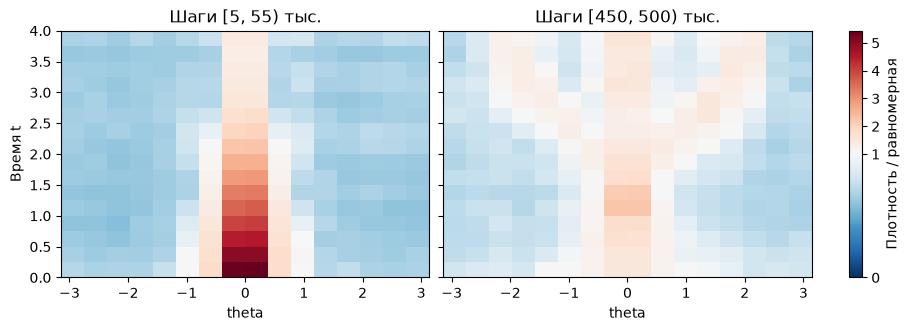

In [7]:
key = 8_192, 100, "rad"
with np.load(paths[key] / "sampling_histograms.npz") as histograms:
    steps = histograms["steps"]
    counts = histograms["counts"]
    theta_edges = histograms["theta_edges"]
    time_edges = histograms["time_edges"]

np.testing.assert_array_equal(steps, sampling_stats[key]["step"])
totals = counts.sum(axis=(1, 2), keepdims=True)
assert ((totals > 0) & (totals <= key[0])).all()
relative_density = counts / totals * (counts.shape[1] * counts.shape[2])

windows = ((5_000, 55_000), (450_000, 500_000))
densities = [
    relative_density[(steps >= start) & (steps < end)].mean(axis=0)
    for start, end in windows
]
scale = TwoSlopeNorm(vmin=0, vcenter=1, vmax=max(density.max() for density in densities))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True, layout="constrained")
for ax, density, (start, end) in zip(axes, densities, windows, strict=True):
    image = ax.pcolormesh(theta_edges, time_edges, density.T, norm=scale, cmap="RdBu_r")
    ax.set(xlabel="theta", title=f"Шаги [{start // 1000}, {end // 1000}) тыс.")
axes[0].set_ylabel("Время t")
fig.colorbar(image, ax=axes, label="Плотность / равномерная")
plt.show()

В начале адаптации точки заметно сгущаются около theta = 0 при малых t. К концу обучения концентрация слабее и охватывает более поздние срезы.

## Итоги

- **RAD позволил сократить N в четыре раза при ошибке ниже 3%.** С периодом 100 и 8 192 точками ошибка составила 2,76% за 77,74 мин. Парный равномерный запуск дал 73,89% за 70,94 мин. При 16 384 точках RAD дал 2,46% за 78,29 мин против 72,17% у парного контроля.
- **Выигрыш по полному времени пока мал.** Лучший равномерный запуск дал 1,95% за 79,42 мин при 32 768 точках и периоде 100. Вариант RAD на 8 192 точках занял примерно на 1,7 мин (2,1%) меньше при большей ошибке. Частый отбор RAD занимал 5,1-5,7 мин за запуск по внутреннему таймеру, редкий около 0,5-0,6 мин.
- **Эффект зависит от N и периода.** При 32 768 точках и периоде 100 RAD дал 22,07% против 1,95% у равномерной выборки. При периоде 1 000 ни один вариант не достиг 5%.
- Для каждой комбинации выполнен один запуск с seed 42. Разброс точности и времени между повторами неизвестен. В метаданных серии стоит git_dirty=true, поэтому хеш коммита сам по себе не фиксирует состояние рабочего дерева при обучении.